Dataset Link: https://www.kaggle.com/datasets/notshrirang/spotify-million-song-dataset/data

In [9]:
!pip install kaggle -q

**Importing the Dependencies**

In [10]:
import os
import json

import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from wordcloud import WordCloud
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

**Data Collection**

In [11]:
import os
import json
from getpass import getpass

# Securely prompt you for your Kaggle credentials
kaggle_username = input("Please enter your Kaggle Username: ").strip()
kaggle_key = getpass("Please paste your Kaggle API Key (from the website): ").strip()

if kaggle_username and kaggle_key:
    # Define the config data
    config_data = {
        "username": kaggle_username,
        "key": kaggle_key
    }

    # Create directory and write the config file
    kaggle_dir = os.path.expanduser('~/.kaggle')
    os.makedirs(kaggle_dir, exist_ok=True)

    config_path = os.path.join(kaggle_dir, 'kaggle.json')
    with open(config_path, 'w') as f:
        json.dump(config_data, f)

    # Restrict file permissions
    os.chmod(config_path, 0o600)
    print("\nkaggle.json successfully generated and configured in ~/.kaggle!")
else:
    print("\nError: Both username and key must be provided.")

Please enter your Kaggle Username: Ezra Ogechi
Please paste your Kaggle API Key (from the website): ··········

kaggle.json successfully generated and configured in ~/.kaggle!


In [12]:
import json
import os

# Load the config from the secure directory to maintain compatibility with your next cells
with open(os.path.expanduser('~/.kaggle/kaggle.json'), 'r') as f:
    kaggle_config = json.load(f)

kaggle_config.keys()

dict_keys(['username', 'key'])

In [13]:
# Set the environment variables (optional but good practice to ensure the CLI and library both detect it)
os.environ['KAGGLE_USERNAME'] = kaggle_config['username']
os.environ['KAGGLE_KEY'] = kaggle_config['key']

In [14]:
# loadig the dataset using kaggle api
!kaggle datasets download notshrirang/spotify-million-song-dataset

Dataset URL: https://www.kaggle.com/datasets/notshrirang/spotify-million-song-dataset
License(s): CC0-1.0
100% 20.7M/20.7M [00:00<00:00, 51.6MB/s]



In [15]:
!ls

sample_data  spotify-million-song-dataset.zip


In [16]:
with zipfile.ZipFile('spotify-million-song-dataset.zip', 'r') as zip_ref:
    zip_ref.extractall()

In [17]:
# loading the dataset to a pandas dataframe
df = pd.read_csv("/content/spotify_millsongdata.csv")

**Initial Understanding**

In [18]:
df.shape

(57650, 4)

In [19]:
df.head()

,artist,song,link,text
0,ABBA,Ahe's My Kind Of Girl,/a/abba/ahes+my+kind+of+girl_20598417.html,"Look at her face, it's a wonderful face \r\nA..."
1,ABBA,"Andante, Andante",/a/abba/andante+andante_20002708.html,"Take it easy with me, please \r\nTouch me gen..."
2,ABBA,As Good As New,/a/abba/as+good+as+new_20003033.html,I'll never know why I had to go \r\nWhy I had...
3,ABBA,Bang,/a/abba/bang_20598415.html,Making somebody happy is a question of give an...
4,ABBA,Bang-A-Boomerang,/a/abba/bang+a+boomerang_20002668.html,Making somebody happy is a question of give an...


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57650 entries, 0 to 57649
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   artist  57650 non-null  object
 1   song    57650 non-null  object
 2   link    57650 non-null  object
 3   text    57650 non-null  object
dtypes: object(4)
memory usage: 1.8+ MB


In [21]:
df.isnull().sum()

,0
artist,0
song,0
link,0
text,0


In [22]:
# Top artists and songs
top_artists = df['artist'].value_counts().head(10)
print("\nTop 10 Artists:")
print(top_artists)


Top 10 Artists:
artist
Donna Summer        191
Gordon Lightfoot    189
Bob Dylan           188
George Strait       188
Loretta Lynn        187
Alabama             187
Cher                187
Reba Mcentire       187
Chaka Khan          186
Dean Martin         186
Name: count, dtype: int64


In [23]:
df = df.sample(10000)

df = df.drop('link', axis=1).reset_index(drop=True)

In [24]:
df.shape

(10000, 3)

In [25]:
df.head()

,artist,song,text
0,Queens Of The Stone Age,Auto Pilot,Silent hell on the marble slab \r\nThe best t...
1,Black Sabbath,End Of The Beginning,Is this the end of the beginning? \r\nOr the ...
2,Oasis,Rockin' Chair,I'm older than I wish to be \r\nThis town hol...
3,Starship,Send A Message,"In a line of fire I stand and wait for you, I ..."
4,Vertical Horizon,The Man Who Would Be Santa,And the man who would be Santa slips into the ...


In [26]:
# WordCloud for song lyrics
all_lyrics = " ".join(df['text'].dropna())
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(all_lyrics)

WordCloud to visualize the most common words in the lyrics.

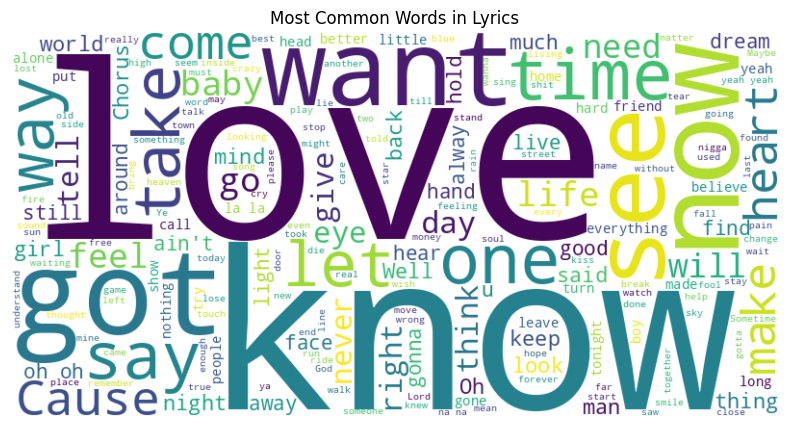

In [27]:
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.title("Most Common Words in Lyrics")
plt.show()

**Data Preprocessing**

In [28]:
# download nltk data
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [29]:
stop_words = set(stopwords.words('english'))

In [30]:
def preprocess_text(text):
    # Remove special characters and numbers
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    # Convert to lowercase
    text = text.lower()
    # Tokenize and remove stopwords
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stop_words]
    return " ".join(tokens)

In [31]:
# Apply preprocessing to lyrics
df['cleaned_text'] = df['text'].apply(preprocess_text)

In [32]:
df.head()

,artist,song,text,cleaned_text
0,Queens Of The Stone Age,Auto Pilot,Silent hell on the marble slab \r\nThe best t...,silent hell marble slab best trip ive ever hig...
1,Black Sabbath,End Of The Beginning,Is this the end of the beginning? \r\nOr the ...,end beginning beginning end losing control win...
2,Oasis,Rockin' Chair,I'm older than I wish to be \r\nThis town hol...,im older wish town holds life try find another...
3,Starship,Send A Message,"In a line of fire I stand and wait for you, I ...",line fire stand wait cant hold long searchin e...
4,Vertical Horizon,The Man Who Would Be Santa,And the man who would be Santa slips into the ...,man would santa slips room hour daylights yet ...


In [33]:
# Vectorization with TF-IDF
tfidf_vectorizer = TfidfVectorizer(max_features=5000)
tfidf_matrix = tfidf_vectorizer.fit_transform(df['cleaned_text'])

In [34]:
# Compute Cosine Similarity
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

In [35]:
# Recommendation Function
def recommend_songs(song_name, cosine_sim=cosine_sim, df=df, top_n=5):
    # Find the index of the song
    idx = df[df['song'].str.lower() == song_name.lower()].index
    if len(idx) == 0:
        return "Song not found in the dataset!"   # can be reworked to compare for songs not present in the dataset
    idx = idx[0]

    # Get similarity scores
    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    sim_scores = sim_scores[1:top_n+1]

    # Get song indices
    song_indices = [i[0] for i in sim_scores]

    # Return top n similar songs
    return df[['artist', 'song']].iloc[song_indices]

In [36]:
df["song"][2]

"Rockin' Chair"

In [37]:
# Example Recommendation
song_title = "For The First Time"
print(f"Recommendations for the song '{song_title}':")
recommendations = recommend_songs(song_title)
print(recommendations)


Recommendations for the song 'Blinded By Rainbows':
               artist                       song
4409        Foreigner  Feels Like The First Time
2836    Conway Twitty         First Things First
7761    Lionel Richie                        Why
8986  John Mellencamp            I Saw You First
6703          Squeeze          First Thing Wrong
